# 04 — Studi Kasus: DKI Jakarta (ISPU Harian 2024–2025)

**Fokus:** bagaimana kualitas udara **harian** di **5 kota administrasi DKI Jakarta** selama **Januari 2024 – November 2025** (2 tahun), diukur dengan **ISPU** (Indeks Standar Pencemar Udara, Permen LHK No. 14/2020).

> **Penting — ISPU ≠ IKU.** Notebook 03 memakai **IKU** tahunan (skala 0–100, makin tinggi makin baik). Notebook ini memakai **ISPU** harian (skala 0–500+, **makin tinggi makin buruk**). Keduanya tidak dicampur.
>
> Sumber: *Data Indeks Standar Pencemar Udara (ISPU) di Provinsi DKI Jakarta*, Dinas Lingkungan Hidup DKI Jakarta — portal **Satu Data Jakarta** (`satudata.jakarta.go.id`). Data ditarik otomatis lewat API resmi portal.

## 0. Setup & pengambilan data

1. **Unduh** seluruh baris ISPU harian dari API Satu Data Jakarta (paginasi, 3.501 baris) → `data/raw/`.
2. **Bersihkan** → `data/processed/`. Aturan:
   - Pisahkan kode stasiun (`DKI1`–`DKI5`) dan petakan ke kota administrasi.
   - Bangun kolom tanggal dari `periode_data` (YYYYMM) + `tanggal`.
   - Konversi kolom polutan & `max` (= nilai ISPU) ke numerik (`N/A`/`null` → kosong).
   - **Kualitas data:** nilai ISPU `0` tanpa polutan apa pun = *placeholder* "tidak ada data" → diubah ke kosong.
   - Buang 1 baris dengan tanggal tidak valid.

In [1]:
from pathlib import Path
import io, json, time
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = ROOT / "data" / "raw"; RAW.mkdir(parents=True, exist_ok=True)
PROC = ROOT / "data" / "processed"; PROC.mkdir(parents=True, exist_ok=True)
IMG = ROOT / "images"; IMG.mkdir(exist_ok=True)

RAW_ISPU = RAW / "jakarta_ispu_harian_2024_2025.csv"
HEADERS = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                         "(KHTML, like Gecko) Chrome/126.0.0.0 Safari/537.36",
           "Accept": "application/json", "Content-Type": "application/json",
           "Origin": "https://satudata.jakarta.go.id",
           "Referer": "https://satudata.jakarta.go.id/"}
API = "https://satudata.jakarta.go.id/backend/api/v2/satudata/detail"
PAGE_URL = "data-indeks-standar-pencemar-udara-ispu-di-provinsi-dki-jakarta"

def fetch_ispu(per_page=100):
    sess = requests.Session(); sess.headers.update(HEADERS)
    rows, page = [], 1
    while True:
        payload = {"kategori": "dataset", "page_url": PAGE_URL, "data_no": page,
                   "per_page": per_page,
                   "table_params": {"page": page, "per_page": per_page,
                                    "sort_field": None, "sort_order": None, "filters": {}}}
        r = sess.post(API, json=payload, timeout=60); r.raise_for_status()
        d = json.loads(r.content.decode("utf-8-sig"))
        fd = d.get("filedata") or []
        total = int(d.get("totalFiledata") or 0)
        if not fd:
            break
        rows.extend(fd)
        if len(rows) >= total:
            break
        page += 1; time.sleep(0.25)
    return pd.DataFrame(rows).drop(columns=["rn"], errors="ignore")

if RAW_ISPU.exists():
    raw = pd.read_csv(RAW_ISPU, dtype=str)
    print("Mentah lokal dipakai:", RAW_ISPU.name, raw.shape)
else:
    raw = fetch_ispu()
    raw.to_csv(RAW_ISPU, index=False, encoding="utf-8-sig")
    print("Diunduh dari API:", raw.shape)
raw.head(3)

Mentah lokal dipakai: jakarta_ispu_harian_2024_2025.csv (3501, 13)


,periode_data,bulan,tanggal,stasiun,pm_sepuluh,pm_duakomalima,sulfur_dioksida,karbon_monoksida,ozon,nitrogen_dioksida,max,parameter_pencemar_kritis,kategori
0,202401,01,21,DKI3 Jagakarsa,51,65,45,9,8,79,79,NaN,SEDANG
1,202401,01,22,DKI3 Jagakarsa,27,34,45,5,8,56,56,NaN,SEDANG
2,202401,01,23,DKI3 Jagakarsa,NaN,52,46,6,9,51,52,PM25,SEDANG


In [2]:
STASIUN_MAP = {"DKI1": "DKI1 Bundaran HI", "DKI2": "DKI2 Kelapa Gading",
               "DKI3": "DKI3 Jagakarsa", "DKI4": "DKI4 Lubang Buaya",
               "DKI5": "DKI5 Kebon Jeruk"}
KOTA_MAP = {"DKI1": "Jakarta Pusat", "DKI2": "Jakarta Utara", "DKI3": "Jakarta Selatan",
            "DKI4": "Jakarta Timur", "DKI5": "Jakarta Barat"}
POLUTAN = ["pm_sepuluh", "pm_duakomalima", "sulfur_dioksida", "karbon_monoksida",
           "ozon", "nitrogen_dioksida"]

df = raw.copy()
df["kode_stasiun"] = df["stasiun"].str.extract(r"(DKI\d)")
df["stasiun"] = df["kode_stasiun"].map(STASIUN_MAP)
df["kota_adm"] = df["kode_stasiun"].map(KOTA_MAP)
tgl = df["tanggal"].str.strip().str.zfill(2)
df["tanggal_dt"] = pd.to_datetime(df["periode_data"].str.strip() + tgl,
                                  format="%Y%m%d", errors="coerce")
for c in POLUTAN + ["max"]:
    df[c] = pd.to_numeric(df[c].replace({"N/A": np.nan, "null": np.nan, "": np.nan}), errors="coerce")
df["ispu"] = df["max"]
df["kategori"] = df["kategori"].replace({"N/A": np.nan, "TIDAK ADA DATA": np.nan})
df["polutan_kritis"] = df["parameter_pencemar_kritis"].replace({"null": np.nan, "PM25": "PM2.5"})

df = df.drop_duplicates(["kode_stasiun", "tanggal_dt"], keep="first")
n_zero = int((df["ispu"] == 0).sum())
df.loc[df["ispu"] == 0, "ispu"] = np.nan
df = df.dropna(subset=["tanggal_dt"]).copy()

KAT_ORDER = {"BAIK": 0, "SEDANG": 1, "TIDAK SEHAT": 2, "SANGAT TIDAK SEHAT": 3, "BERBAHAYA": 4}
df["kategori_rank"] = df["kategori"].map(KAT_ORDER)

KEEP = ["tanggal_dt", "periode_data", "kode_stasiun", "stasiun", "kota_adm"] + POLUTAN + \
       ["ispu", "kategori", "kategori_rank", "polutan_kritis"]
clean = df[KEEP].sort_values(["tanggal_dt", "kode_stasiun"]).reset_index(drop=True)
clean.to_csv(PROC / "jakarta_ispu_harian_clean.csv", index=False, encoding="utf-8-sig")

print("placeholder ISPU=0 -> kosong :", n_zero)
print("Rentang tanggal :", clean['tanggal_dt'].min().date(), "->", clean['tanggal_dt'].max().date())
print("Jumlah baris    :", len(clean), "| ISPU kosong:", clean['ispu'].isna().sum())
print("Stasiun         :", sorted(clean['stasiun'].unique()))
clean.head(5)

placeholder ISPU=0 -> kosong : 13
Rentang tanggal : 2024-01-01 -> 2025-11-30
Jumlah baris    : 3500 | ISPU kosong: 20
Stasiun         : ['DKI1 Bundaran HI', 'DKI2 Kelapa Gading', 'DKI3 Jagakarsa', 'DKI4 Lubang Buaya', 'DKI5 Kebon Jeruk']


,tanggal_dt,periode_data,kode_stasiun,stasiun,kota_adm,pm_sepuluh,pm_duakomalima,sulfur_dioksida,karbon_monoksida,ozon,nitrogen_dioksida,ispu,kategori,kategori_rank,polutan_kritis
0,2024-01-01,202401,DKI1,DKI1 Bundaran HI,Jakarta Pusat,64.0,89.0,52.0,9.0,13.0,30.0,89.0,SEDANG,1.0,PM2.5
1,2024-01-01,202401,DKI2,DKI2 Kelapa Gading,Jakarta Utara,67.0,103.0,34.0,18.0,26.0,NaN,103.0,TIDAK SEHAT,2.0,PM2.5
2,2024-01-01,202401,DKI3,DKI3 Jagakarsa,Jakarta Selatan,65.0,89.0,14.0,54.0,13.0,NaN,89.0,SEDANG,1.0,PM2.5
3,2024-01-01,202401,DKI4,DKI4 Lubang Buaya,Jakarta Timur,74.0,110.0,10.0,20.0,24.0,10.0,110.0,TIDAK SEHAT,2.0,PM2.5
4,2024-01-01,202401,DKI5,DKI5 Kebon Jeruk,Jakarta Barat,58.0,99.0,40.0,18.0,55.0,12.0,99.0,SEDANG,1.0,PM2.5


## 1. Ringkasan: ISPU per stasiun / kota administrasi

In [3]:
STASIUN_ORDER = ["DKI1 Bundaran HI", "DKI2 Kelapa Gading", "DKI3 Jagakarsa",
                 "DKI4 Lubang Buaya", "DKI5 Kebon Jeruk"]
valid = clean.dropna(subset=["ispu"]).copy()

tabel = (valid.groupby("stasiun")["ispu"]
         .agg(hari="count", rata_rata="mean", median="median", maks="max", min="min")
         .round(2).reindex(STASIUN_ORDER))
tabel["kota_adm"] = valid.groupby("stasiun")["kota_adm"].first().reindex(STASIUN_ORDER)
print("== ISPU per stasiun (2024-01 s.d. 2025-11) ==")
print(tabel.to_string())

kat = pd.crosstab(valid["stasiun"], valid["kategori"]).reindex(STASIUN_ORDER)
kat_pct = (kat.div(kat.sum(axis=1), axis=0) * 100).round(1)
print("\n== % hari menurut kategori per stasiun ==")
print(kat_pct.to_string())

print("\n== distribusi kategori keseluruhan ==")
print(valid["kategori"].value_counts().reindex(
    ["BAIK", "SEDANG", "TIDAK SEHAT", "SANGAT TIDAK SEHAT"]).to_string())

== ISPU per stasiun (2024-01 s.d. 2025-11) ==
                    hari  rata_rata  median   maks   min         kota_adm
stasiun                                                                  
DKI1 Bundaran HI     699      73.04    74.0  120.0  26.0    Jakarta Pusat
DKI2 Kelapa Gading   697      73.92    74.0  132.0  23.0    Jakarta Utara
DKI3 Jagakarsa       696      72.45    70.0  202.0  26.0  Jakarta Selatan
DKI4 Lubang Buaya    690      70.81    69.0  187.0  19.0    Jakarta Timur
DKI5 Kebon Jeruk     698      76.56    78.0  157.0  14.0    Jakarta Barat

== % hari menurut kategori per stasiun ==
kategori            BAIK  SANGAT TIDAK SEHAT  SEDANG  TIDAK SEHAT
stasiun                                                          
DKI1 Bundaran HI    15.3                 0.0    78.3          6.4
DKI2 Kelapa Gading  11.5                 0.0    78.6          9.9
DKI3 Jagakarsa       4.9                 0.1    90.2          4.7
DKI4 Lubang Buaya   16.1                 0.0    72.3         11

## 2. Tren ISPU bulanan per stasiun

Garis putus-putus menandai ambang kategori **Baik (≤50)**, **Sedang (51–100)**, dan **Tidak Sehat (>100)**.

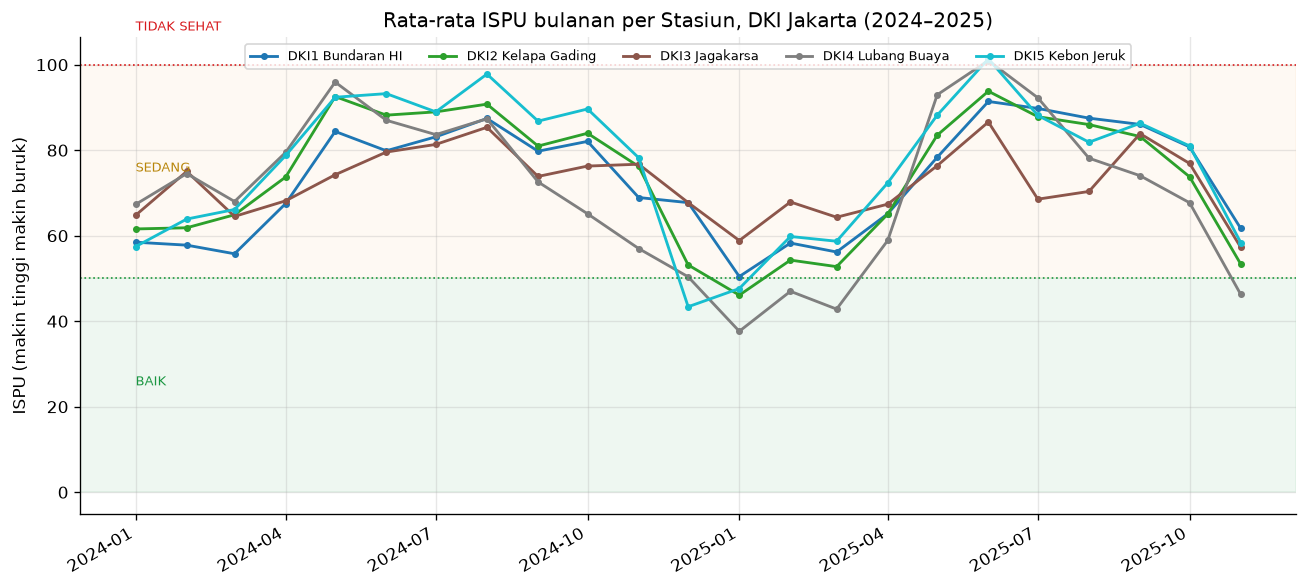

In [4]:
valid["bulan"] = valid["tanggal_dt"].dt.to_period("M").dt.to_timestamp()
piv = valid.pivot_table(index="bulan", columns="stasiun", values="ispu", aggfunc="mean")[STASIUN_ORDER]

fig, ax = plt.subplots(figsize=(11, 5))
cmap = plt.cm.tab10(np.linspace(0, 1, 5))
for st, c in zip(STASIUN_ORDER, cmap):
    ax.plot(piv.index, piv[st], marker="o", ms=3.2, lw=1.7, color=c, label=st)
ax.axhspan(0, 50, color="#1a9641", alpha=0.07)
ax.axhspan(50, 100, color="#fdae61", alpha=0.07)
ax.axhline(50, color="#1a9641", ls=":", lw=1)
ax.axhline(100, color="#d7191c", ls=":", lw=1)
ax.text(piv.index[0], 25, "BAIK", color="#1a9641", fontsize=8)
ax.text(piv.index[0], 75, "SEDANG", color="#b8860b", fontsize=8)
ax.text(piv.index[0], 108, "TIDAK SEHAT", color="#d7191c", fontsize=8)
ax.set_title("Rata-rata ISPU bulanan per Stasiun, DKI Jakarta (2024–2025)")
ax.set_ylabel("ISPU (makin tinggi makin buruk)"); ax.set_xlabel("")
ax.legend(fontsize=8, ncol=5, loc="upper center")
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(IMG / "04_ispu_tren_bulanan.png"); plt.show()

## 3. Komposisi kategori ISPU per bulan

Berapa persen hari tiap bulan masuk kategori Baik / Sedang / Tidak Sehat — memperlihatkan **pola musiman**.

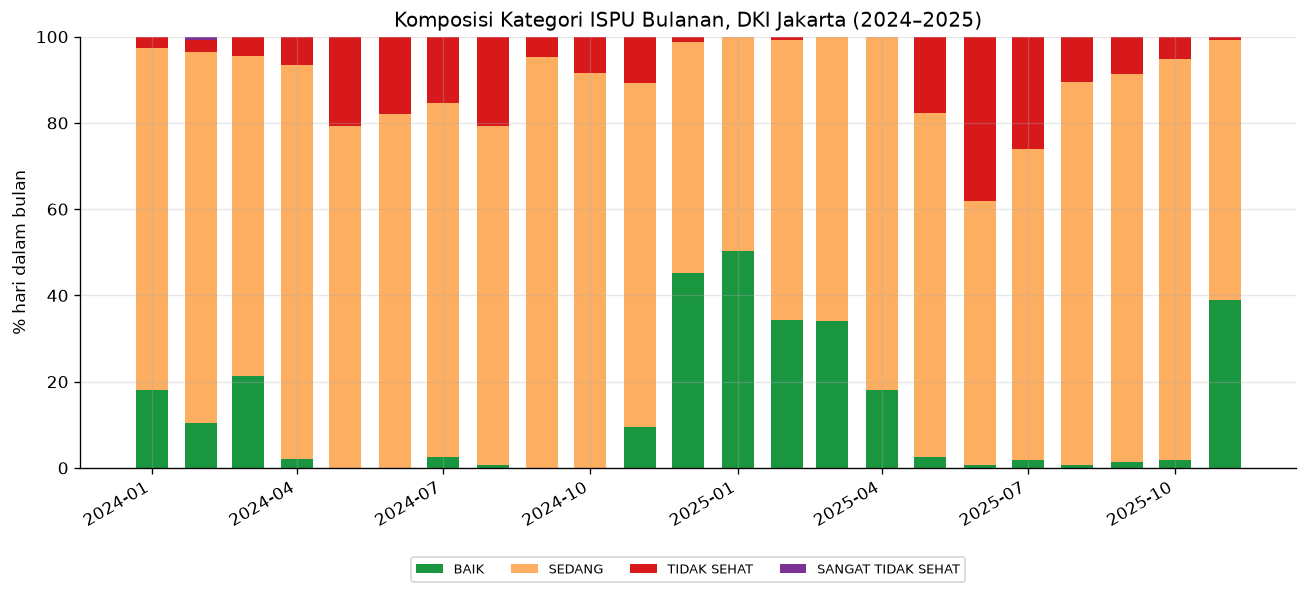

In [5]:
cats = ["BAIK", "SEDANG", "TIDAK SEHAT", "SANGAT TIDAK SEHAT"]
ct = (valid.groupby(["bulan", "kategori"]).size().unstack(fill_value=0).reindex(columns=cats, fill_value=0))
share = ct.div(ct.sum(axis=1), axis=0) * 100
cat_colors = {"BAIK": "#1a9641", "SEDANG": "#fdae61",
              "TIDAK SEHAT": "#d7191c", "SANGAT TIDAK SEHAT": "#7b3294"}

fig, ax = plt.subplots(figsize=(11, 5))
bottom = np.zeros(len(share))
for c in cats:
    ax.bar(share.index, share[c], bottom=bottom, width=20, color=cat_colors[c], label=c)
    bottom += share[c].values
ax.set_ylim(0, 100); ax.set_ylabel("% hari dalam bulan")
ax.set_title("Komposisi Kategori ISPU Bulanan, DKI Jakarta (2024–2025)")
ax.legend(fontsize=8, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.28))
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(IMG / "04_ispu_kategori_bulanan.png", bbox_inches="tight"); plt.show()

## 4. Perbandingan antar stasiun (2 tahun)

Kiri: rata-rata ISPU. Kanan: persentase hari **Tidak Sehat ke atas** (ISPU > 100).

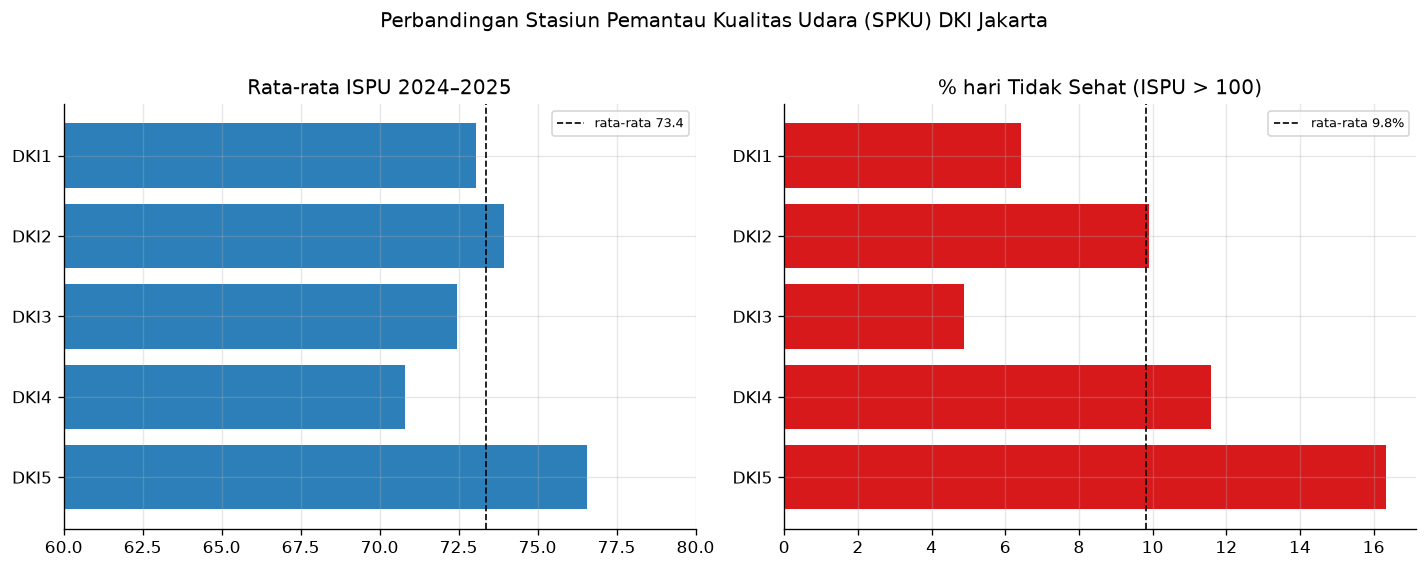

                    rata_rata  pct_buruk
stasiun                                 
DKI1 Bundaran HI        73.04       6.44
DKI2 Kelapa Gading      73.92       9.90
DKI3 Jagakarsa          72.45       4.89
DKI4 Lubang Buaya       70.81      11.59
DKI5 Kebon Jeruk        76.56      16.33


In [6]:
valid["buruk"] = valid["kategori"].isin(["TIDAK SEHAT", "SANGAT TIDAK SEHAT"])
agg = (valid.groupby("stasiun")
       .agg(rata_rata=("ispu", "mean"), pct_buruk=("buruk", "mean"))
       .reindex(STASIUN_ORDER))
agg["pct_buruk"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
lab = [s[:4] for s in STASIUN_ORDER]
axes[0].barh(lab, agg["rata_rata"], color="#2c7fb8")
axes[0].axvline(agg["rata_rata"].mean(), color="k", ls="--", lw=1,
                label=f"rata-rata {agg['rata_rata'].mean():.1f}")
axes[0].set_xlim(60, 80); axes[0].set_title("Rata-rata ISPU 2024–2025"); axes[0].legend(fontsize=8)
axes[0].invert_yaxis()

axes[1].barh(lab, agg["pct_buruk"], color="#d7191c")
axes[1].axvline(agg["pct_buruk"].mean(), color="k", ls="--", lw=1,
                label=f"rata-rata {agg['pct_buruk'].mean():.1f}%")
axes[1].set_title("% hari Tidak Sehat (ISPU > 100)"); axes[1].legend(fontsize=8)
axes[1].invert_yaxis()
fig.suptitle("Perbandingan Stasiun Pemantau Kualitas Udara (SPKU) DKI Jakarta", y=1.02)
fig.tight_layout(); fig.savefig(IMG / "04_ispu_perbandingan_stasiun.png", bbox_inches="tight"); plt.show()
print(agg.round(2).to_string())

## 5. Parameter pencemar kritis

Parameter dengan nilai ISPU tertinggi pada tiap hari menentukan penyebab utama polusi.

                jumlah_hari  persen
polutan_kritis                     
PM2.5                  2955    86.0
SO2                     225     6.5
PM10                    176     5.1
O3                       52     1.5
NO2                      27     0.8
CO                        1     0.0


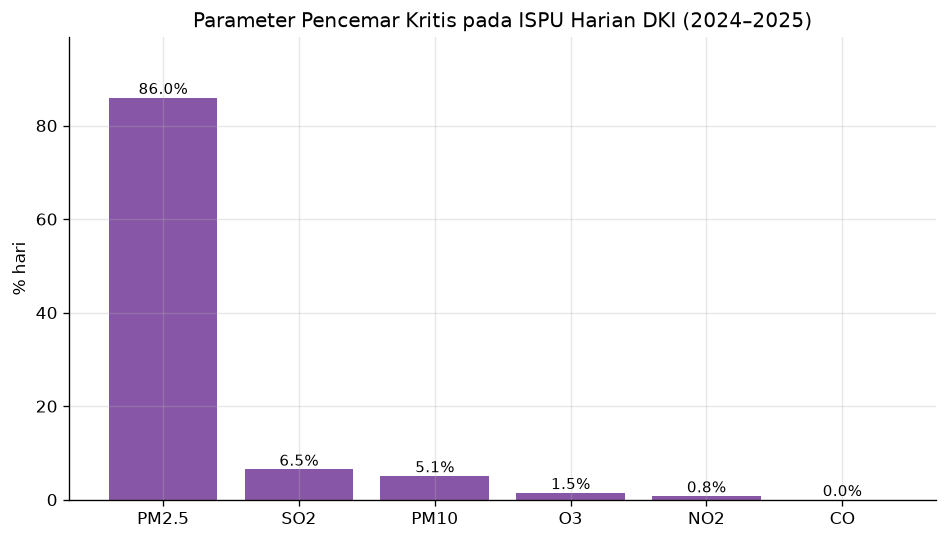

In [7]:
pc = valid["polutan_kritis"].value_counts(dropna=True)
sh = (pc / pc.sum() * 100).round(1)
print(pd.DataFrame({"jumlah_hari": pc, "persen": sh}).to_string())

fig, ax = plt.subplots(figsize=(8, 4.6))
bars = ax.bar(sh.index, sh.values, color="#8856a7")
ax.bar_label(bars, fmt="%.1f%%", fontsize=9)
ax.set_ylabel("% hari"); ax.set_title("Parameter Pencemar Kritis pada ISPU Harian DKI (2024–2025)")
ax.set_ylim(0, sh.max() * 1.15)
fig.tight_layout(); fig.savefig(IMG / "04_ispu_polutan_kritis.png"); plt.show()

## 6. Heatmap stasiun × bulan

Warna hijau = udara lebih bersih, merah = lebih buruk.

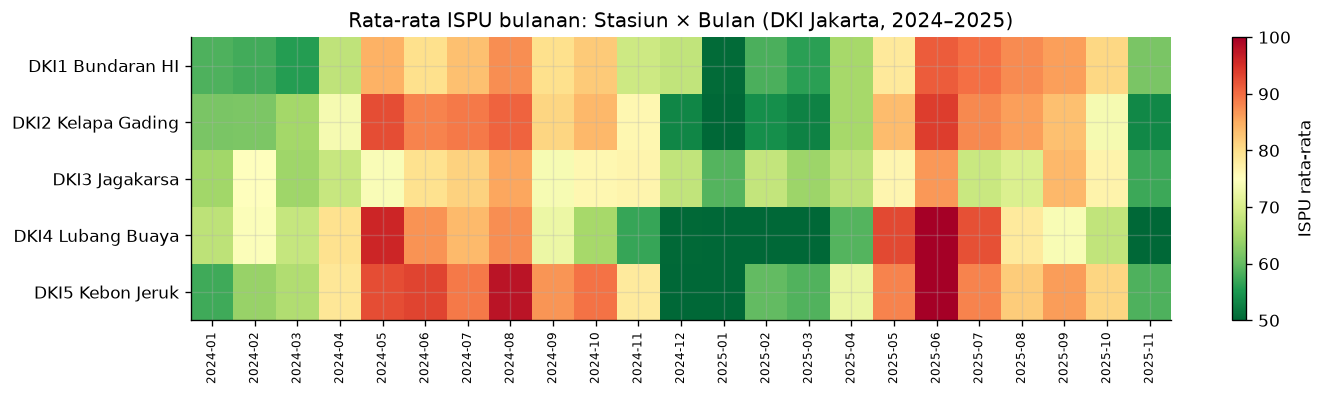

In [8]:
hm = valid.pivot_table(index="stasiun", columns="bulan", values="ispu") \
          .reindex(STASIUN_ORDER)
fig, ax = plt.subplots(figsize=(12, 3.4))
im = ax.imshow(hm.values, aspect="auto", cmap="RdYlGn_r", vmin=50, vmax=100)
ax.set_xticks(range(len(hm.columns)),
              [d.strftime("%Y-%m") for d in hm.columns], rotation=90, fontsize=7)
ax.set_yticks(range(len(hm.index)), hm.index)
fig.colorbar(im, ax=ax, label="ISPU rata-rata")
ax.set_title("Rata-rata ISPU bulanan: Stasiun × Bulan (DKI Jakarta, 2024–2025)")
fig.tight_layout(); fig.savefig(IMG / "04_ispu_heatmap_bulanan.png", bbox_inches="tight"); plt.show()

## 7. Pola harian: hari kerja vs akhir pekan

Apakah udara membaik saat lalu lintas lebih sepi di akhir pekan?

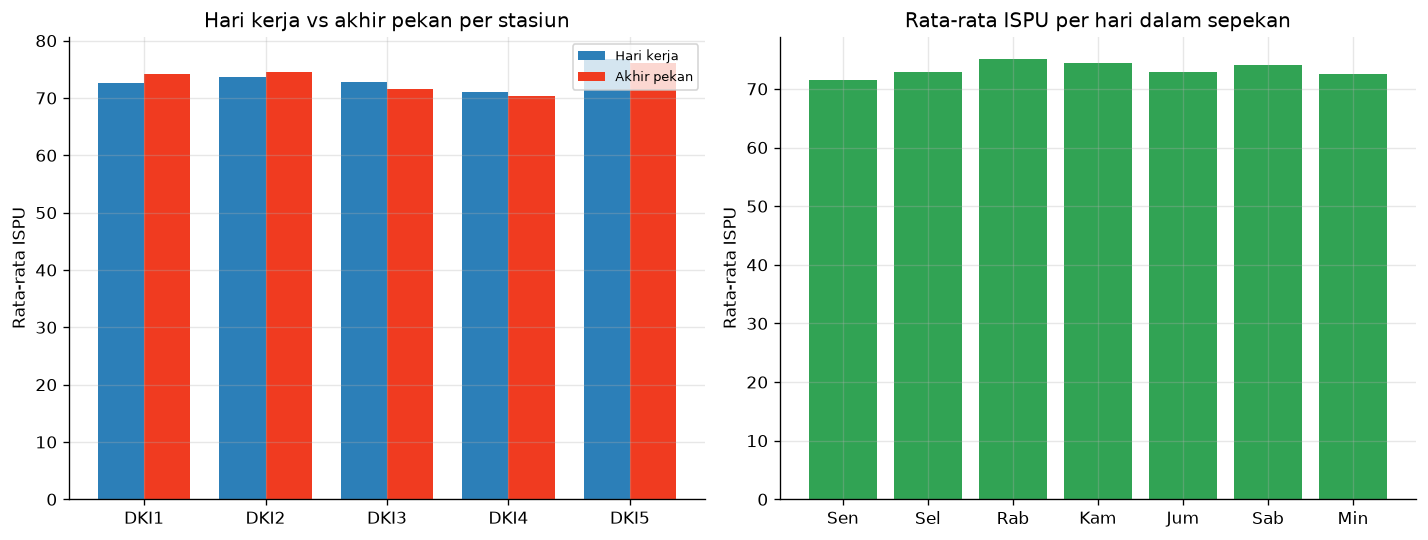

Rata-rata ISPU hari kerja : 73.36
Rata-rata ISPU akhir pekan: 73.37


In [9]:
valid["akhir_pekan"] = valid["tanggal_dt"].dt.dayofweek >= 5

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
grp = valid.groupby(["stasiun", "akhir_pekan"])["ispu"].mean().unstack().reindex(STASIUN_ORDER)
x = np.arange(len(STASIUN_ORDER)); w = 0.38
axes[0].bar(x - w/2, grp[False], w, label="Hari kerja", color="#2c7fb8")
axes[0].bar(x + w/2, grp[True], w, label="Akhir pekan", color="#f03b20")
axes[0].set_xticks(x, [s[:4] for s in STASIUN_ORDER])
axes[0].set_ylabel("Rata-rata ISPU"); axes[0].set_title("Hari kerja vs akhir pekan per stasiun")
axes[0].legend(fontsize=8)

hari = ["Sen", "Sel", "Rab", "Kam", "Jum", "Sab", "Min"]
dow = valid.groupby(valid["tanggal_dt"].dt.dayofweek)["ispu"].mean()
axes[1].bar(range(7), dow.values, color="#31a354")
axes[1].set_xticks(range(7), hari)
axes[1].set_ylabel("Rata-rata ISPU"); axes[1].set_title("Rata-rata ISPU per hari dalam sepekan")
fig.tight_layout(); fig.savefig(IMG / "04_ispu_pola_harian.png", bbox_inches="tight"); plt.show()

print("Rata-rata ISPU hari kerja :", round(valid.loc[~valid['akhir_pekan'], 'ispu'].mean(), 2))
print("Rata-rata ISPU akhir pekan:", round(valid.loc[valid['akhir_pekan'], 'ispu'].mean(), 2))

## Catatan & keterbatasan

- **Periode:** data berakhir **30 November 2025**; tidak ada data 2026 pada sumber ini. Dua tahun penuh (2024 + Jan–Nov 2025).
- **Metrik:** ISPU (makin tinggi makin buruk) **berbeda** dari IKU pada notebook 03 (makin tinggi makin baik). Angka kedua notebook tidak boleh dibandingkan langsung.
- **Cakupan:** 5 stasiun mewakili 5 kota administrasi (DKI1 Pusat, DKI2 Utara, DKI3 Selatan, DKI4 Timur, DKI5 Barat). Kab. Adm. Kepulauan Seribu tidak memiliki stasiun ISPU tetap.
- **Kualitas data:** 13 baris bernilai 0 tanpa polutan = placeholder "tidak ada data" (sudah dikosongkan); 20 dari 3.500 baris ISPU kosong; 1 stasiun–hari duplikat dibuang.
- **Atribusi:** Dinas Lingkungan Hidup DKI Jakarta via Satu Data Jakarta. Kategori mengikuti Permen LHK No. 14/2020.

In [10]:
for f in sorted(IMG.glob("04_*.png")):
    print(" ", f.name)

  04_ispu_heatmap_bulanan.png
  04_ispu_kategori_bulanan.png
  04_ispu_perbandingan_stasiun.png
  04_ispu_pola_harian.png
  04_ispu_polutan_kritis.png
  04_ispu_tren_bulanan.png
